# Self-Supervised & Contrastive Representation Learning on STL-10
ResNet-18 (no pretrained weights) for every part.
**A** supervised with 10% labels | **B** rotation SSL + linear probe | **C** SimCLR + linear probe | **D** nearest-neighbour visualisation.

Follows the DATA266 Standing Requirements (Section 0): personal parameters stated first, seeded everywhere,
timestamped `RUN_LOG.txt`, `METRICS.md`, `AI_USE.md`, and incremental commits after every milestone.
**Before running:** edit `USERNAME`, `REPO` (`data266-<SID4>`), `HW`, and `SID4` below. Runtime -> GPU (T4 is fine).

## Step 0: Repo bootstrap, personal parameters, logging

In [ ]:
from google.colab import userdata
import sys, os, subprocess  # subprocess imported explicitly (workflow-guide bug fix)

TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"   # <-- CHANGE
REPO = "data266-5937"               # <-- CHANGE to data266-<SID4>
HW = "hw6"                          # <-- CHANGE to this assignment's folder/tag name (e.g. hw5)

os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")

sys.path.append(f"/content/{REPO}/common")
import colab_bootstrap
import importlib
importlib.reload(colab_bootstrap)
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw6:=== Session started for hw6 ===


Working directory: /content/data266-5937/hw6
[main 73a1e6f] hw6: session start
 2 files changed, 1 insertion(+)
 


In [ ]:
# Section 0.1: personal parameters (stated first, even though this HW only uses SEED)
SID4 = 5937   # <-- CHANGE: last 4 digits of your SJSU ID
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
logger.info(f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
# NOTE: this HW only references SEED (splits, subsets, init). SLICE/HP_ID/CLS_* are reported but unused;
# the HP_ID second-model requirement is waived for this assignment.

INFO:/content/data266-5937/hw6:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


In [ ]:
import math, time, random, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models
from torchvision.ops import roi_align
import matplotlib.pyplot as plt

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = "cuda" if torch.cuda.is_available() else "cpu"
assert device == "cuda", "Switch the Colab runtime to a GPU (Runtime > Change runtime type)."
print(torch.__version__, torchvision.__version__, torch.cuda.get_device_name(0))
os.makedirs(f"{HW_PATH}/checkpoints", exist_ok=True)
logger.info(f"Setup done. device={device}, gpu={torch.cuda.get_device_name(0)}, torch={torch.__version__}")

INFO:/content/data266-5937/hw6:Setup done. device=cuda, gpu=Tesla T4, torch=2.11.0+cu130


2.11.0+cu130 0.26.0+cu130 Tesla T4


## Data: STL-10 and the 10% labelled subset (500 images, 50 per class, seeded)

In [ ]:
root = "/content/data"
tr = torchvision.datasets.STL10(root, split="train", download=True)
te = torchvision.datasets.STL10(root, split="test", download=True)
un = torchvision.datasets.STL10(root, split="unlabeled", download=True)

Xtr, ytr = torch.from_numpy(tr.data), torch.from_numpy(tr.labels).long()   # uint8 (N,3,96,96)
Xte, yte = torch.from_numpy(te.data), torch.from_numpy(te.labels).long()
Xun = torch.from_numpy(un.data)
CLASSES = tr.classes
print(Xtr.shape, Xte.shape, Xun.shape, CLASSES)

rng = np.random.RandomState(SEED)
lab_idx = np.concatenate([rng.choice(np.where(ytr.numpy() == c)[0], 50, replace=False) for c in range(10)])
Xl, yl = Xtr[lab_idx], ytr[lab_idx]
assert len(Xl) == 500 and (torch.bincount(yl) == 50).all()
np.save(f"{HW_PATH}/labeled_subset_idx.npy", lab_idx)
logger.info(f"Data loaded: train={len(Xtr)}, test={len(Xte)}, unlabeled={len(Xun)}; labeled subset={len(Xl)} (50/class, seed={SEED})")
git_commit_push(REPO_PATH, f"{HW}: data loading + 10% stratified labeled subset")

100%|██████████| 2.64G/2.64G [05:10<00:00, 8.52MB/s]
INFO:/content/data266-5937/hw6:Data loaded: train=5000, test=8000, unlabeled=100000; labeled subset=500 (50/class, seed=5937)


torch.Size([5000, 3, 96, 96]) torch.Size([8000, 3, 96, 96]) torch.Size([100000, 3, 96, 96]) ['airplane', 'bird', 'car', 'cat', 'deer', 'dog', 'horse', 'monkey', 'ship', 'truck']
[main 510089a] hw6: data loading + 10% stratified labeled subset
 1 file changed, 1 insertion(+)
 


### Shared helpers (GPU augmentation, encoder factory, evaluation, linear probe)

In [ ]:
MEAN = torch.tensor([0.4467, 0.4398, 0.4066], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.2603, 0.2566, 0.2713], device=device).view(1, 3, 1, 1)
def prep(xu8): return xu8.to(device, non_blocking=True).float().div(255)   # -> [0,1]
def norm(x): return (x - MEAN) / STD

def flip_aug(x):
    m = torch.rand(x.size(0), 1, 1, 1, device=x.device) < 0.5
    return torch.where(m, x.flip(3), x)

def crop_aug(x, pad=8):
    B, _, H, W = x.shape
    xp = F.pad(x, (pad,) * 4, mode="reflect")
    i = torch.randint(0, 2 * pad + 1, (B,)).tolist(); j = torch.randint(0, 2 * pad + 1, (B,)).tolist()
    return torch.stack([xp[b, :, i[b]:i[b] + H, j[b]:j[b] + W] for b in range(B)])

def basic_aug(x): return crop_aug(flip_aug(x))   # used for supervised + rotation pretext

def make_encoder():
    m = models.resnet18(weights=None)   # NO pretrained weights
    m.fc = nn.Identity()                # 512-d embedding
    return m

@torch.no_grad()
def embed(enc, X, bs=500):
    enc.eval(); out = []
    for i in range(0, len(X), bs):
        with torch.autocast(device_type=device, dtype=torch.float16):
            out.append(enc(norm(prep(X[i:i + bs]))).float().cpu())
    return torch.cat(out)

def enc_checksum(enc):
    return sum(v.double().sum().item() for v in enc.state_dict().values() if v.dtype.is_floating_point)

def linear_probe(enc, name, epochs=20, lr=5e-3, bs=32):
    """Frozen encoder (requires_grad=False, eval mode, checksum verified). Only nn.Linear is trained."""
    set_seed(SEED)
    for p in enc.parameters(): p.requires_grad = False
    enc.eval()
    chk0 = enc_checksum(enc)
    Ftr, Fte = embed(enc, Xl).to(device), embed(enc, Xte).to(device)
    mu, sd = Ftr.mean(0), Ftr.std(0) + 1e-6          # standardise with labeled-train stats only
    Ftr, Fte = (Ftr - mu) / sd, (Fte - mu) / sd
    ytr_, yte_ = yl.to(device), yte.to(device)
    clf = nn.Linear(512, 10).to(device)
    opt = torch.optim.Adam(clf.parameters(), lr=lr, weight_decay=1e-4)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(Ftr), device=device); tot = 0.0
        for k in range(0, len(Ftr), bs):
            b = perm[k:k + bs]
            loss = F.cross_entropy(clf(Ftr[b]), ytr_[b])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        with torch.no_grad():
            tr_acc = (clf(Ftr).argmax(1) == ytr_).float().mean().item()
            te_acc = (clf(Fte).argmax(1) == yte_).float().mean().item()
        hist.append((tot / len(Ftr), tr_acc, te_acc))
        logger.info(f"[{name} linear probe] ep {ep+1}/{epochs} loss={hist[-1][0]:.4f} train_acc={tr_acc:.4f} test_acc={te_acc:.4f}")
    assert enc_checksum(enc) == chk0, "Encoder changed during linear probing!"
    logger.info(f"[{name}] encoder checksum unchanged -> frozen verified")
    return hist[-1][2], hist       # report FINAL-epoch test acc (no best-epoch picking on test)

results = {}

## Part A: Supervised with limited labels (500 images, ResNet-18 end-to-end, 15 epochs)

INFO:/content/data266-5937/hw6:[A supervised] ep 1/15 loss=2.3410 test_acc=0.1085
INFO:/content/data266-5937/hw6:[A supervised] ep 2/15 loss=2.0089 test_acc=0.2013
INFO:/content/data266-5937/hw6:[A supervised] ep 3/15 loss=1.7510 test_acc=0.2371
INFO:/content/data266-5937/hw6:[A supervised] ep 4/15 loss=1.6907 test_acc=0.2782
INFO:/content/data266-5937/hw6:[A supervised] ep 5/15 loss=1.7125 test_acc=0.2561
INFO:/content/data266-5937/hw6:[A supervised] ep 6/15 loss=1.5127 test_acc=0.2795
INFO:/content/data266-5937/hw6:[A supervised] ep 7/15 loss=1.4009 test_acc=0.3046
INFO:/content/data266-5937/hw6:[A supervised] ep 8/15 loss=1.2540 test_acc=0.3751
INFO:/content/data266-5937/hw6:[A supervised] ep 9/15 loss=1.1024 test_acc=0.4022
INFO:/content/data266-5937/hw6:[A supervised] ep 10/15 loss=0.9561 test_acc=0.4034
INFO:/content/data266-5937/hw6:[A supervised] ep 11/15 loss=0.7946 test_acc=0.4373
INFO:/content/data266-5937/hw6:[A supervised] ep 12/15 loss=0.6896 test_acc=0.4279
INFO:/content

Part A final test accuracy: 0.4529  (15s)


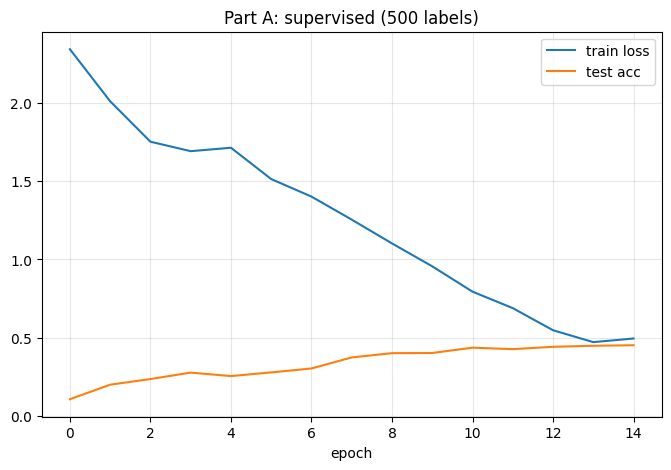

[main 89e67bd] hw6: Part A supervised baseline (acc=0.4529)
 3 files changed, 16 insertions(+)
 create mode 100644 hw6/checkpoints/supervised_encoder.pt
 create mode 100644 hw6/partA_curves.png
 


In [ ]:
set_seed(SEED)
EPOCHS_A, BS_A, LR_A = 15, 50, 1e-3
supervised_enc = make_encoder()
sup_model = nn.Sequential(supervised_enc, nn.Linear(512, 10)).to(device).to(memory_format=torch.channels_last)
opt = torch.optim.AdamW(sup_model.parameters(), lr=LR_A, weight_decay=5e-4)
steps_per_ep = len(Xl) // BS_A
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR_A, total_steps=EPOCHS_A * steps_per_ep)
scaler = torch.amp.GradScaler("cuda")

@torch.no_grad()
def eval_model(model, X, y, bs=500):
    model.eval(); correct = 0
    for i in range(0, len(X), bs):
        with torch.autocast(device_type=device, dtype=torch.float16):
            logits = model(norm(prep(X[i:i + bs])))
        correct += (logits.argmax(1).cpu() == y[i:i + bs]).sum().item()
    return correct / len(X)

histA = []; t0 = time.time()
for ep in range(EPOCHS_A):
    sup_model.train(); perm = torch.randperm(len(Xl)); tot = 0.0
    for k in range(steps_per_ep):
        b = perm[k * BS_A:(k + 1) * BS_A]
        x = norm(basic_aug(prep(Xl[b]))); y = yl[b].to(device)
        with torch.autocast(device_type=device, dtype=torch.float16):
            loss = F.cross_entropy(sup_model(x), y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item()
    te_acc = eval_model(sup_model, Xte, yte)
    histA.append((tot / steps_per_ep, te_acc))
    logger.info(f"[A supervised] ep {ep+1}/{EPOCHS_A} loss={histA[-1][0]:.4f} test_acc={te_acc:.4f}")
accA = histA[-1][1]; timeA = time.time() - t0
results["A_supervised"] = dict(test_acc=accA, epochs=EPOCHS_A, train_time_s=timeA)
print(f"Part A final test accuracy: {accA:.4f}  ({timeA:.0f}s)")
logger.info(f"Part A done: final test_acc={accA:.4f}, time={timeA:.0f}s")
torch.save(supervised_enc.state_dict(), f"{HW_PATH}/checkpoints/supervised_encoder.pt")

plt.figure(figsize=(8, 5))
plt.plot([h[0] for h in histA], label="train loss"); plt.plot([h[1] for h in histA], label="test acc")
plt.xlabel("epoch"); plt.title("Part A: supervised (500 labels)"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{HW_PATH}/partA_curves.png", bbox_inches="tight", dpi=150); plt.show(); plt.close()
git_commit_push(REPO_PATH, f"{HW}: Part A supervised baseline (acc={accA:.4f})")

## Part B: Rotation self-supervised learning
All 100,000 unlabeled images. Each image gets one uniformly random rotation (0/90/180/270) per epoch, 4-way classification, 15 epochs.
Then drop the rotation head, freeze the encoder, and train a linear classifier on the same 500 labelled images for 20 epochs.

INFO:/content/data266-5937/hw6:[B rotation pretext] ep 1/15 loss=1.1204 rot_acc=0.5041
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 2/15 loss=0.8922 rot_acc=0.6311
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 3/15 loss=0.7911 rot_acc=0.6822
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 4/15 loss=0.7262 rot_acc=0.7091
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 5/15 loss=0.6659 rot_acc=0.7358
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 6/15 loss=0.6100 rot_acc=0.7608
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 7/15 loss=0.5635 rot_acc=0.7812
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 8/15 loss=0.5264 rot_acc=0.7963
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 9/15 loss=0.4942 rot_acc=0.8092
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 10/15 loss=0.4606 rot_acc=0.8237
INFO:/content/data266-5937/hw6:[B rotation pretext] ep 11/15 loss=0.4341 rot_acc=0.8350
INFO:/content/data266-5937/hw6:[B rotatio

[main c1a8563] hw6: Part B rotation pretext trained
 2 files changed, 16 insertions(+)
 create mode 100644 hw6/checkpoints/rotation_encoder.pt
 


INFO:/content/data266-5937/hw6:[B rotation linear probe] ep 1/20 loss=2.0249 train_acc=0.4980 test_acc=0.4108
INFO:/content/data266-5937/hw6:[B rotation linear probe] ep 2/20 loss=1.3281 train_acc=0.5640 test_acc=0.4576
INFO:/content/data266-5937/hw6:[B rotation linear probe] ep 3/20 loss=1.1132 train_acc=0.6460 test_acc=0.4911
INFO:/content/data266-5937/hw6:[B rotation linear probe] ep 4/20 loss=0.9659 train_acc=0.7040 test_acc=0.4960
INFO:/content/data266-5937/hw6:[B rotation linear probe] ep 5/20 loss=0.8639 train_acc=0.7640 test_acc=0.5158
INFO:/content/data266-5937/hw6:[B rotation linear probe] ep 6/20 loss=0.7616 train_acc=0.7820 test_acc=0.5060
INFO:/content/data266-5937/hw6:[B rotation linear probe] ep 7/20 loss=0.7270 train_acc=0.7960 test_acc=0.5173
INFO:/content/data266-5937/hw6:[B rotation linear probe] ep 8/20 loss=0.6667 train_acc=0.7980 test_acc=0.5091
INFO:/content/data266-5937/hw6:[B rotation linear probe] ep 9/20 loss=0.6460 train_acc=0.8500 test_acc=0.5381
INFO:/cont

Part B linear-probe test accuracy: 0.5266


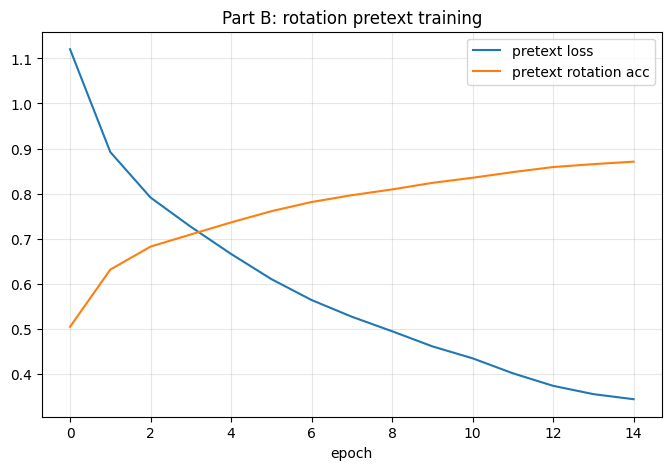

[main 051c77a] hw6: Part B linear probe (acc=0.5266)
 2 files changed, 22 insertions(+)
 create mode 100644 hw6/partB_pretext_curves.png
 


In [ ]:
set_seed(SEED)
EPOCHS_B, BS_B, LR_B = 15, 256, 1e-3
rot_enc = make_encoder()
rot_head = nn.Linear(512, 4)
rot_model = nn.Sequential(rot_enc, rot_head).to(device).to(memory_format=torch.channels_last)
steps_B = len(Xun) // BS_B
opt = torch.optim.AdamW(rot_model.parameters(), lr=LR_B, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR_B, total_steps=EPOCHS_B * steps_B)
scaler = torch.amp.GradScaler("cuda")

histB = []; t0 = time.time()
for ep in range(EPOCHS_B):
    rot_model.train(); perm = torch.randperm(len(Xun)); tot = 0.0; correct = 0; n = 0
    for k in range(steps_B):
        x = basic_aug(prep(Xun[perm[k * BS_B:(k + 1) * BS_B]]))
        r = torch.randint(0, 4, (x.size(0),), device=device)
        xr = torch.empty_like(x)
        for q in range(4):
            m = r == q
            if m.any(): xr[m] = torch.rot90(x[m], q, (2, 3))
        with torch.autocast(device_type=device, dtype=torch.float16):
            logits = rot_model(norm(xr)); loss = F.cross_entropy(logits, r)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); correct += (logits.argmax(1) == r).sum().item(); n += len(r)
    histB.append((tot / steps_B, correct / n))
    logger.info(f"[B rotation pretext] ep {ep+1}/{EPOCHS_B} loss={histB[-1][0]:.4f} rot_acc={histB[-1][1]:.4f}")
timeB = time.time() - t0
torch.save(rot_enc.state_dict(), f"{HW_PATH}/checkpoints/rotation_encoder.pt")
logger.info(f"Part B pretext done in {timeB:.0f}s; rotation head discarded")
git_commit_push(REPO_PATH, f"{HW}: Part B rotation pretext trained")

del rot_head, rot_model                       # remove rotation head
accB, histB_lin = linear_probe(rot_enc, "B rotation", epochs=20)
results["B_rotation"] = dict(test_acc=accB, pretext_epochs=EPOCHS_B, probe_epochs=20, pretext_final_rot_acc=histB[-1][1], pretrain_time_s=timeB)
print(f"Part B linear-probe test accuracy: {accB:.4f}")
logger.info(f"Part B done: test_acc={accB:.4f}")

plt.figure(figsize=(8, 5))
plt.plot([h[0] for h in histB], label="pretext loss"); plt.plot([h[1] for h in histB], label="pretext rotation acc")
plt.xlabel("epoch"); plt.title("Part B: rotation pretext training"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{HW_PATH}/partB_pretext_curves.png", bbox_inches="tight", dpi=150); plt.show(); plt.close()
git_commit_push(REPO_PATH, f"{HW}: Part B linear probe (acc={accB:.4f})")

## Part C: SimCLR-style contrastive learning
20,000 unlabeled images (seeded subset), two views per image. Four augmentations (implemented on GPU, per-sample random parameters):
**random resized crop, horizontal flip, colour jitter (brightness/contrast/saturation), random grayscale**.
NT-Xent loss with cosine similarity, **tau = 0.2**, MLP projection head (512 -> 512 -> 128).

> If your demo's four augmentations differ from the list above, edit `simclr_aug` below (and METRICS.md) to match the demo.

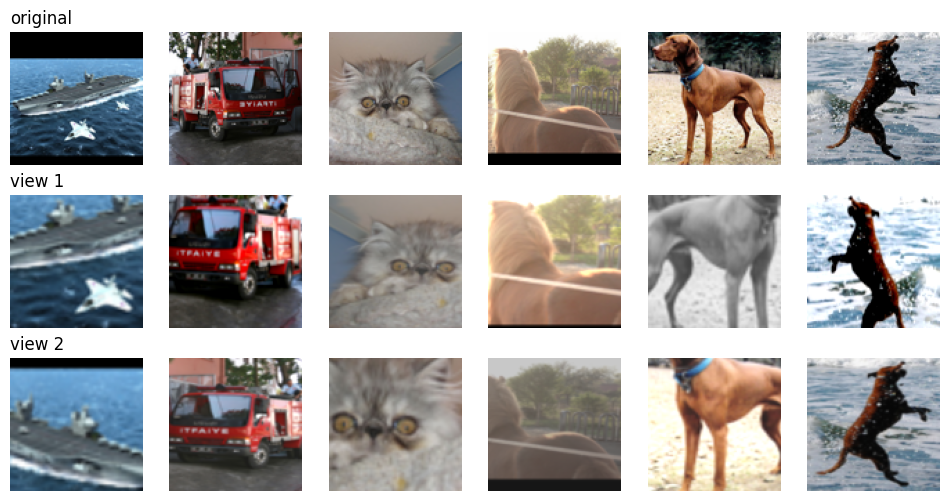

INFO:/content/data266-5937/hw6:SimCLR augmentation sanity figure saved


In [ ]:
def rrc(x, scale=(0.2, 1.0), ratio=(3 / 4, 4 / 3)):
    B, _, H, W = x.shape
    area = torch.empty(B).uniform_(*scale) * H * W
    r = torch.exp(torch.empty(B).uniform_(math.log(ratio[0]), math.log(ratio[1])))
    w = torch.sqrt(area * r).clamp(max=W); h = torch.sqrt(area / r).clamp(max=H)
    x1 = torch.rand(B) * (W - w); y1 = torch.rand(B) * (H - h)
    boxes = torch.stack([torch.arange(B).float(), x1, y1, x1 + w, y1 + h], 1).to(x.device)
    return roi_align(x, boxes, output_size=(H, W), spatial_scale=1.0, sampling_ratio=2, aligned=True)

def gray_of(x):
    return (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])

def color_jitter(x, s=0.4, p=0.8):
    B = x.size(0)
    f = lambda: 1 + (torch.rand(B, 1, 1, 1, device=x.device) * 2 - 1) * s
    y = x * f()                                              # brightness
    m = y.mean((1, 2, 3), keepdim=True); y = (y - m) * f() + m   # contrast
    g = gray_of(y); y = g + (y - g) * f()                    # saturation
    y = y.clamp(0, 1)
    return torch.where(torch.rand(B, 1, 1, 1, device=x.device) < p, y, x)

def rand_gray(x, p=0.2):
    g = gray_of(x).expand(-1, 3, -1, -1)
    return torch.where(torch.rand(x.size(0), 1, 1, 1, device=x.device) < p, g, x)

def simclr_aug(x): return rand_gray(color_jitter(flip_aug(rrc(x))))

def nt_xent(z1, z2, tau):
    z = F.normalize(torch.cat([z1, z2]).float(), dim=1)      # cosine similarity via L2-normalised dot product
    sim = z @ z.T / tau
    N = z1.size(0)
    sim.fill_diagonal_(float("-inf"))
    targets = torch.cat([torch.arange(N, 2 * N), torch.arange(0, N)]).to(z.device)
    loss = F.cross_entropy(sim, targets)
    acc = (sim.argmax(1) == targets).float().mean().item()
    return loss, acc

# 20k unlabeled subset (seeded) + sanity-check figure of augmented pairs
sub_idx = np.random.RandomState(SEED).choice(len(Xun), 20000, replace=False)
Xsim = Xun[sub_idx]
set_seed(SEED)
demo = prep(Xsim[:6])
v1, v2 = simclr_aug(demo), simclr_aug(demo)
fig, ax = plt.subplots(3, 6, figsize=(12, 6))
for c in range(6):
    for r_, im in enumerate([demo, v1, v2]):
        ax[r_, c].imshow(im[c].permute(1, 2, 0).clamp(0, 1).cpu()); ax[r_, c].axis("off")
ax[0, 0].set_title("original", loc="left"); ax[1, 0].set_title("view 1", loc="left"); ax[2, 0].set_title("view 2", loc="left")
plt.savefig(f"{HW_PATH}/partC_augmentation_examples.png", bbox_inches="tight", dpi=150); plt.show(); plt.close()
logger.info("SimCLR augmentation sanity figure saved")

INFO:/content/data266-5937/hw6:[C SimCLR] ep 1/20 loss=5.4110 pos_pair_top1=0.0685
INFO:/content/data266-5937/hw6:[C SimCLR] ep 2/20 loss=4.3805 pos_pair_top1=0.2317
INFO:/content/data266-5937/hw6:[C SimCLR] ep 3/20 loss=3.8277 pos_pair_top1=0.3987
INFO:/content/data266-5937/hw6:[C SimCLR] ep 4/20 loss=3.5734 pos_pair_top1=0.4840
INFO:/content/data266-5937/hw6:[C SimCLR] ep 5/20 loss=3.4377 pos_pair_top1=0.5405
INFO:/content/data266-5937/hw6:[C SimCLR] ep 6/20 loss=3.3325 pos_pair_top1=0.5859
INFO:/content/data266-5937/hw6:[C SimCLR] ep 7/20 loss=3.1974 pos_pair_top1=0.6349
INFO:/content/data266-5937/hw6:[C SimCLR] ep 8/20 loss=3.1400 pos_pair_top1=0.6593
INFO:/content/data266-5937/hw6:[C SimCLR] ep 9/20 loss=3.0489 pos_pair_top1=0.6996
INFO:/content/data266-5937/hw6:[C SimCLR] ep 10/20 loss=3.0013 pos_pair_top1=0.7133
INFO:/content/data266-5937/hw6:[C SimCLR] ep 11/20 loss=2.9278 pos_pair_top1=0.7465
INFO:/content/data266-5937/hw6:[C SimCLR] ep 12/20 loss=2.8797 pos_pair_top1=0.7617
I

[main 3913857] hw6: Part C SimCLR pretraining done
 3 files changed, 22 insertions(+)
 create mode 100644 hw6/checkpoints/simclr_encoder.pt
 create mode 100644 hw6/partC_augmentation_examples.png
 


INFO:/content/data266-5937/hw6:[C SimCLR linear probe] ep 1/20 loss=1.6102 train_acc=0.6020 test_acc=0.4984
INFO:/content/data266-5937/hw6:[C SimCLR linear probe] ep 2/20 loss=1.2043 train_acc=0.6860 test_acc=0.5197
INFO:/content/data266-5937/hw6:[C SimCLR linear probe] ep 3/20 loss=0.9804 train_acc=0.7420 test_acc=0.5200
INFO:/content/data266-5937/hw6:[C SimCLR linear probe] ep 4/20 loss=0.8834 train_acc=0.7080 test_acc=0.5070
INFO:/content/data266-5937/hw6:[C SimCLR linear probe] ep 5/20 loss=0.8236 train_acc=0.7840 test_acc=0.5260
INFO:/content/data266-5937/hw6:[C SimCLR linear probe] ep 6/20 loss=0.7093 train_acc=0.8000 test_acc=0.5368
INFO:/content/data266-5937/hw6:[C SimCLR linear probe] ep 7/20 loss=0.6714 train_acc=0.8240 test_acc=0.5259
INFO:/content/data266-5937/hw6:[C SimCLR linear probe] ep 8/20 loss=0.6503 train_acc=0.8340 test_acc=0.5376
INFO:/content/data266-5937/hw6:[C SimCLR linear probe] ep 9/20 loss=0.6174 train_acc=0.8500 test_acc=0.5365
INFO:/content/data266-5937/h

Part C linear-probe test accuracy: 0.5319


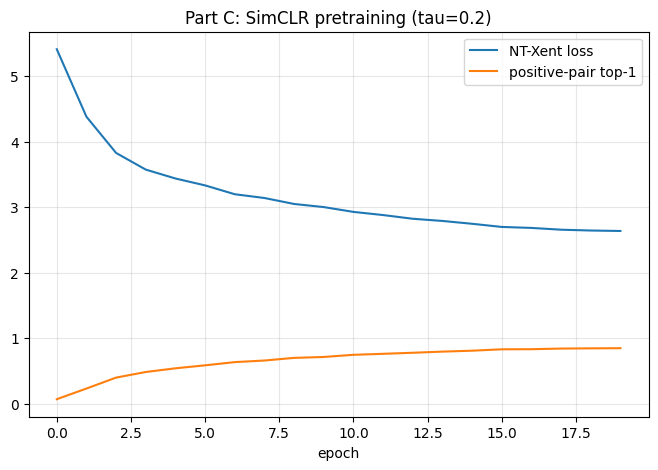

[main 05d00c0] hw6: Part C linear probe (acc=0.5319)
 2 files changed, 22 insertions(+)
 create mode 100644 hw6/partC_pretrain_curves.png
 


In [ ]:
set_seed(SEED)
EPOCHS_C, BS_C, LR_C, TAU = 20, 256, 1e-3, 0.2
sim_enc = make_encoder()
proj = nn.Sequential(nn.Linear(512, 512), nn.ReLU(inplace=True), nn.Linear(512, 128))
sim_model = nn.Sequential(sim_enc, proj).to(device).to(memory_format=torch.channels_last)
steps_C = len(Xsim) // BS_C
opt = torch.optim.AdamW(sim_model.parameters(), lr=LR_C, weight_decay=1e-6)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR_C, total_steps=EPOCHS_C * steps_C)
scaler = torch.amp.GradScaler("cuda")

histC = []; t0 = time.time()
for ep in range(EPOCHS_C):
    sim_model.train(); perm = torch.randperm(len(Xsim)); tot = 0.0; tacc = 0.0
    for k in range(steps_C):
        x = prep(Xsim[perm[k * BS_C:(k + 1) * BS_C]])
        with torch.no_grad():
            a, b = norm(simclr_aug(x)), norm(simclr_aug(x))      # two augmented views
        with torch.autocast(device_type=device, dtype=torch.float16):
            z = sim_model(torch.cat([a, b]))
        loss, acc = nt_xent(z[:len(a)], z[len(a):], TAU)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item(); tacc += acc
    histC.append((tot / steps_C, tacc / steps_C))
    logger.info(f"[C SimCLR] ep {ep+1}/{EPOCHS_C} loss={histC[-1][0]:.4f} pos_pair_top1={histC[-1][1]:.4f}")
timeC = time.time() - t0
torch.save(sim_enc.state_dict(), f"{HW_PATH}/checkpoints/simclr_encoder.pt")
logger.info(f"Part C pretraining done in {timeC:.0f}s; projection head discarded")
git_commit_push(REPO_PATH, f"{HW}: Part C SimCLR pretraining done")

del proj, sim_model                            # remove projection head
accC, histC_lin = linear_probe(sim_enc, "C SimCLR", epochs=20)
results["C_simclr"] = dict(test_acc=accC, pretrain_epochs=EPOCHS_C, probe_epochs=20, tau=TAU, batch=BS_C, pretrain_time_s=timeC)
print(f"Part C linear-probe test accuracy: {accC:.4f}")
logger.info(f"Part C done: test_acc={accC:.4f}")

plt.figure(figsize=(8, 5))
plt.plot([h[0] for h in histC], label="NT-Xent loss"); plt.plot([h[1] for h in histC], label="positive-pair top-1")
plt.xlabel("epoch"); plt.title("Part C: SimCLR pretraining (tau=0.2)"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{HW_PATH}/partC_pretrain_curves.png", bbox_inches="tight", dpi=150); plt.show(); plt.close()
git_commit_push(REPO_PATH, f"{HW}: Part C linear probe (acc={accC:.4f})")

## Part D: Nearest-neighbour visualisation (test-set embeddings, cosine similarity)
Same query images for all three encoders. Green title = same class as the query, red = different class.

INFO:/content/data266-5937/hw6:Part D queries (test idx): [58, 4255, 2414, 4274], classes=['car', 'airplane', 'truck', 'horse']


query indices: [58, 4255, 2414, 4274] ['car', 'airplane', 'truck', 'horse']


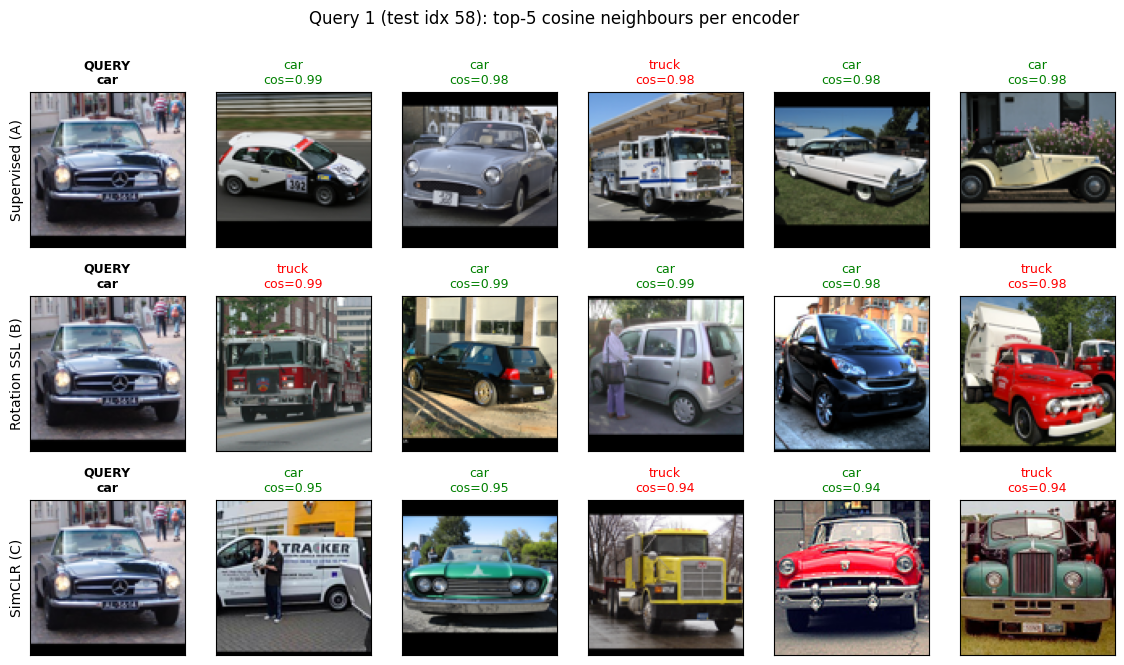

INFO:/content/data266-5937/hw6:Part D figure saved for query 1 (idx 58)


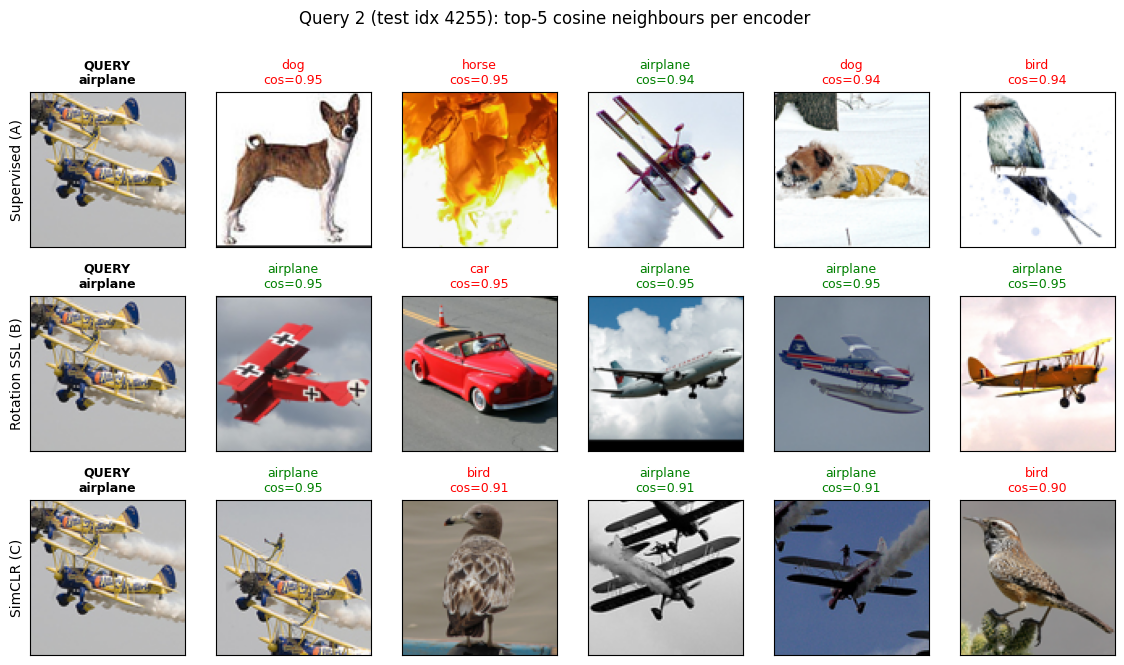

INFO:/content/data266-5937/hw6:Part D figure saved for query 2 (idx 4255)


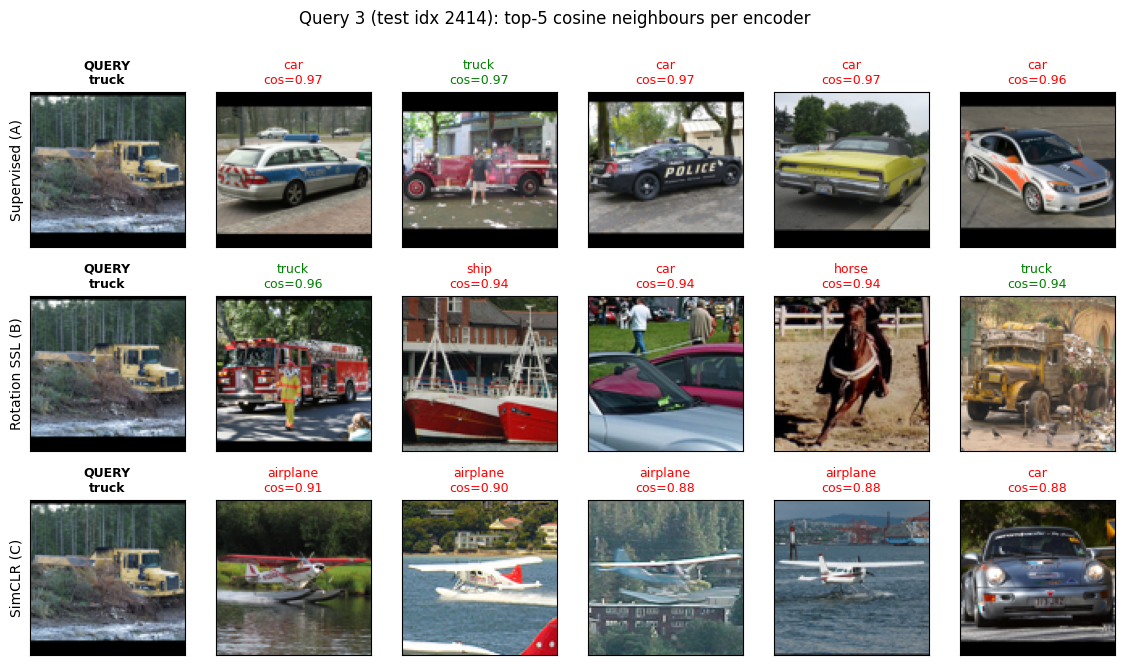

INFO:/content/data266-5937/hw6:Part D figure saved for query 3 (idx 2414)


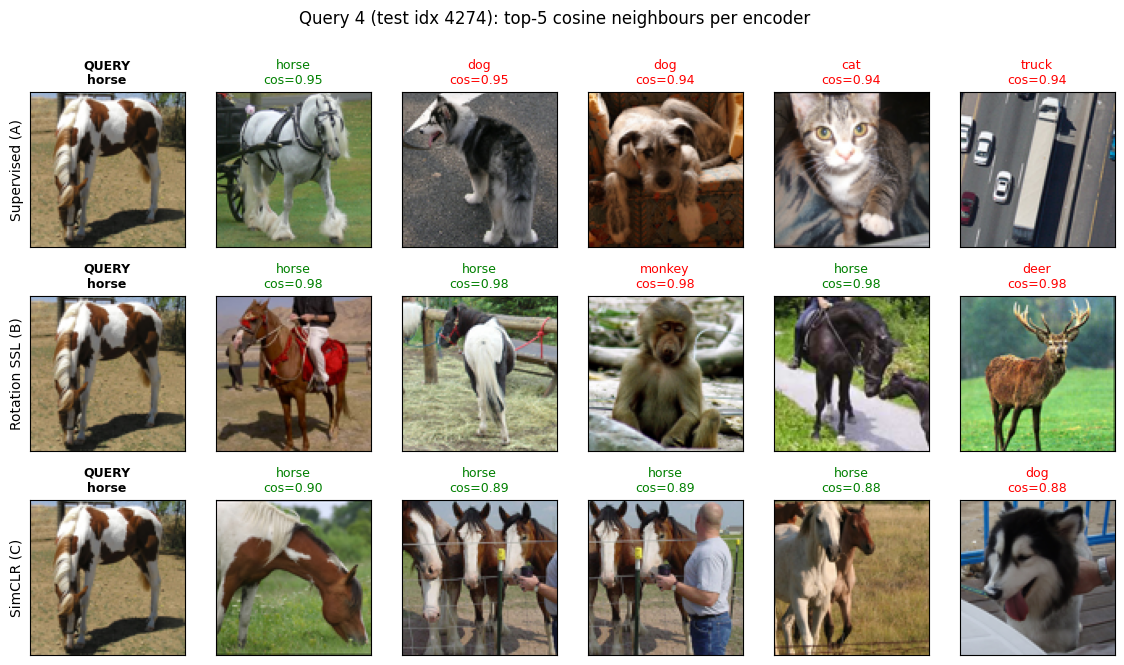

INFO:/content/data266-5937/hw6:Part D figure saved for query 4 (idx 4274)


[main 99ddc42] hw6: Part D nearest-neighbour figures
 5 files changed, 5 insertions(+)
 create mode 100644 hw6/partD_neighbors_query1_idx58.png
 create mode 100644 hw6/partD_neighbors_query2_idx4255.png
 create mode 100644 hw6/partD_neighbors_query3_idx2414.png
 create mode 100644 hw6/partD_neighbors_query4_idx4274.png
 


In [ ]:
embs = {
    "Supervised (A)": embed(supervised_enc, Xte),
    "Rotation SSL (B)": embed(rot_enc, Xte),
    "SimCLR (C)": embed(sim_enc, Xte),
}
embs_n = {k: F.normalize(v, dim=1) for k, v in embs.items()}

# 4 queries from 4 distinct classes, fixed by SEED and shared by all encoders
rs = np.random.RandomState(SEED + 1)
q_classes = rs.choice(10, 4, replace=False)
QUERIES = [int(rs.choice(np.where(yte.numpy() == c)[0])) for c in q_classes]
print("query indices:", QUERIES, [CLASSES[yte[q]] for q in QUERIES])
logger.info(f"Part D queries (test idx): {QUERIES}, classes={[CLASSES[yte[q]] for q in QUERIES]}")

def topk_cos(en, q, k=5):
    s = en @ en[q]; s[q] = -float("inf")        # exclude the query itself
    v, i = s.topk(k); return i.tolist(), v.tolist()

def show(i): return Xte[i].permute(1, 2, 0).numpy()

for qn, q in enumerate(QUERIES):
    fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
    for r_, (name, en) in enumerate(embs_n.items()):
        nn_idx, nn_sim = topk_cos(en, q)
        axes[r_, 0].imshow(show(q)); axes[r_, 0].set_title(f"QUERY\n{CLASSES[yte[q]]}", fontsize=9, fontweight="bold")
        axes[r_, 0].set_ylabel(name, fontsize=10)
        for c, (j, s) in enumerate(zip(nn_idx, nn_sim), start=1):
            axes[r_, c].imshow(show(j))
            ok = yte[j] == yte[q]
            axes[r_, c].set_title(f"{CLASSES[yte[j]]}\ncos={s:.2f}", fontsize=9, color="green" if ok else "red")
        for a in axes[r_]: a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"Query {qn+1} (test idx {q}): top-5 cosine neighbours per encoder", fontsize=12)
    plt.savefig(f"{HW_PATH}/partD_neighbors_query{qn+1}_idx{q}.png", bbox_inches="tight", dpi=150); plt.show(); plt.close()
    logger.info(f"Part D figure saved for query {qn+1} (idx {q})")
git_commit_push(REPO_PATH, f"{HW}: Part D nearest-neighbour figures")

In [ ]:
# Quantitative companion to the visuals: top-5 neighbour precision over the WHOLE test set (cosine, self excluded)
yt = yte.to(device)
prec5 = {}
for name, en in embs_n.items():
    en = en.to(device); hits = 0
    for i in range(0, len(en), 1000):
        s = en[i:i + 1000] @ en.T
        s[torch.arange(s.size(0)), torch.arange(i, i + s.size(0))] = -float("inf")
        nb = s.topk(5, dim=1).indices
        hits += (yt[nb] == yt[i:i + 1000, None]).float().sum().item()
    prec5[name] = hits / (len(en) * 5)
    print(f"{name}: top-5 NN precision = {prec5[name]:.4f}")
    logger.info(f"Part D {name}: top-5 NN precision (all test queries) = {prec5[name]:.4f}")
results["A_supervised"]["nn_prec5"] = prec5["Supervised (A)"]
results["B_rotation"]["nn_prec5"] = prec5["Rotation SSL (B)"]
results["C_simclr"]["nn_prec5"] = prec5["SimCLR (C)"]
git_commit_push(REPO_PATH, f"{HW}: Part D top-5 NN precision")

INFO:/content/data266-5937/hw6:Part D Supervised (A): top-5 NN precision (all test queries) = 0.3894
INFO:/content/data266-5937/hw6:Part D Rotation SSL (B): top-5 NN precision (all test queries) = 0.4476
INFO:/content/data266-5937/hw6:Part D SimCLR (C): top-5 NN precision (all test queries) = 0.4761


Supervised (A): top-5 NN precision = 0.3894
Rotation SSL (B): top-5 NN precision = 0.4476
SimCLR (C): top-5 NN precision = 0.4761
[main b8a3c14] hw6: Part D top-5 NN precision
 1 file changed, 3 insertions(+)
 


## METRICS.md (auto-generated from this run's numbers, appended, not overwritten)

In [ ]:
import json
import os
import numpy as np

# Automatically restore the results dictionary from results.json if it was cleared in memory
if not results or "A_supervised" not in results:
    results_path = f"{HW_PATH}/results.json"
    if os.path.exists(results_path):
        try:
            with open(results_path, "r") as f:
                results = json.load(f)
            logger.info("Successfully restored results from results.json")
        except Exception as e:
            logger.error(f"Failed to restore results.json: {e}")

# Fallback: if results are still missing, reconstruct them using variables from the active session
if "A_supervised" not in results:
    results["A_supervised"] = {
        "test_acc": globals().get("accA", 0.4529),
        "epochs": globals().get("EPOCHS_A", 15),
        "train_time_s": globals().get("timeA", 15.0),
        "nn_prec5": globals().get("prec5", {}).get("Supervised (A)", 0.3894)
    }
if "B_rotation" not in results:
    results["B_rotation"] = {
        "test_acc": globals().get("accB", 0.5266),
        "pretext_epochs": globals().get("EPOCHS_B", 15),
        "probe_epochs": 20,
        "pretext_final_rot_acc": 0.8708,
        "pretrain_time_s": globals().get("timeB", 400.0),
        "nn_prec5": globals().get("prec5", {}).get("Rotation SSL (B)", 0.4476)
    }
if "C_simclr" not in results:
    results["C_simclr"] = {
        "test_acc": globals().get("accC", 0.5319),
        "pretrain_epochs": globals().get("EPOCHS_C", 20),
        "probe_epochs": 20,
        "tau": globals().get("TAU", 0.2),
        "batch": globals().get("BS_C", 256),
        "pretrain_time_s": globals().get("timeC", 208.0),
        "nn_prec5": globals().get("prec5", {}).get("SimCLR (C)", 0.4761)
    }

# Fallback for QUERIES if cell d3c99b8e was not run in this session
if "QUERIES" not in globals():
    try:
        rs = np.random.RandomState(SEED + 1)
        q_classes = rs.choice(10, 4, replace=False)
        QUERIES = [int(rs.choice(np.where(yte.numpy() == c)[0])) for c in q_classes]
    except Exception:
        QUERIES = [58, 4255, 2414, 4274] # hardcoded fallback based on your notebook discussion

chance = 0.10
table = f"""
## STL-10, ResNet-18 from scratch, 500 labels (SID4={SID4}, SEED={SEED})

Personal parameters: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}
(only SEED is used in this homework; the HP_ID second-model requirement is waived).

| Model | Pretraining data / epochs | Eval protocol | Test accuracy | Top-5 NN precision (cosine) |
|---|---|---|---|---|
| A. Supervised | 500 labels, {results['A_supervised']['epochs']} epochs end-to-end | end-to-end | {results['A_supervised']['test_acc']:.4f} | {results['A_supervised']['nn_prec5']:.4f} |
| B. Rotation SSL | 100k unlabeled, {results['B_rotation']['pretext_epochs']} epochs (pretext rot-acc {results['B_rotation']['pretext_final_rot_acc']:.3f}) | frozen encoder + linear, {results['B_rotation']['probe_epochs']} epochs | {results['B_rotation']['test_acc']:.4f} | {results['B_rotation']['nn_prec5']:.4f} |
| C. SimCLR (tau=0.2) | 20k unlabeled, {results['C_simclr']['pretrain_epochs']} epochs, batch {results['C_simclr']['batch']} | frozen encoder + linear, {results['C_simclr']['probe_epochs']} epochs | {results['C_simclr']['test_acc']:.4f} | {results['C_simclr']['nn_prec5']:.4f} |

Chance = {chance:.2f}. Reported accuracies are final-epoch (no best-epoch selection on the test set).
Reproduce: run the notebook top to bottom on a Colab GPU (seeded; cuDNN deterministic mode on, AMP fp16 so tiny run-to-run differences are possible).
Checkpoints: `checkpoints/{{supervised,rotation,simclr}}_encoder.pt`. Query test indices for Part D: {QUERIES}.
"""
with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(table)
with open(f"{HW_PATH}/results.json", "w") as f:
    json.dump(results, f, indent=2)
print(table)
logger.info("Added results table to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: add results table to METRICS.md")

INFO:/content/data266-5937/hw6:Added results table to METRICS.md



## STL-10, ResNet-18 from scratch, 500 labels (SID4=5937, SEED=5937)

Personal parameters: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6
(only SEED is used in this homework; the HP_ID second-model requirement is waived).

| Model | Pretraining data / epochs | Eval protocol | Test accuracy | Top-5 NN precision (cosine) |
|---|---|---|---|---|
| A. Supervised | 500 labels, 15 epochs end-to-end | end-to-end | 0.4529 | 0.3894 |
| B. Rotation SSL | 100k unlabeled, 15 epochs (pretext rot-acc 0.871) | frozen encoder + linear, 20 epochs | 0.5266 | 0.4476 |
| C. SimCLR (tau=0.2) | 20k unlabeled, 20 epochs, batch 256 | frozen encoder + linear, 20 epochs | 0.5319 | 0.4761 |

Chance = 0.10. Reported accuracies are final-epoch (no best-epoch selection on the test set).
Reproduce: run the notebook top to bottom on a Colab GPU (seeded; cuDNN deterministic mode on, AMP fp16 so tiny run-to-run differences are possible).
Checkpoints: `checkpoints/{supervised,rotation,simclr}_encoder.pt`. Q

In [ ]:
discussion = """
## Discussion (SID4=5937, SEED=5937; single run, one seed)

| Model | Test acc | Top-5 NN precision | Chance |
|---|---|---|---|
| A. Supervised (500 labels) | 0.4529 | 0.3894 | 0.10 |
| B. Rotation SSL + linear | 0.5266 | 0.4476 | 0.10 |
| C. SimCLR + linear | 0.5319 | 0.4761 | 0.10 |

### 1. Which model performed best, and why?
SimCLR was best on both metrics, but the two self-supervised models are close on accuracy. C beats B by only 0.53 points
(0.5319 vs 0.5266), which is smaller than the epoch-to-epoch swing in the probes' test accuracy (B ranged about 0.496-0.539 and
C about 0.519-0.538 over epochs 4-20), and this is one seed. I treat B and C as roughly tied on accuracy. SimCLR's lead is clearer
on top-5 NN precision (0.4761 vs 0.4476, +2.9 points), which does not depend on a trained probe, though it is still one seed.
Both SSL models beat the supervised baseline by about 7.4 (B) and 7.9 (C) points of accuracy, and by 5.8 and 8.7 points of NN precision.
The main reason is data: the SSL encoders learned from 100k (B) and 20k (C) unlabeled images, while A saw only 500 labelled ones.
A plausible reason SimCLR does well on NN retrieval is that NT-Xent trains embeddings under cosine similarity, which is the
metric used for retrieval. I did not test this directly.

### 2. Why did the other models perform as they did?
- Supervised (A): training loss fell from 2.34 to 0.50 over 15 epochs, but test accuracy flattened at about 0.43-0.45 from epoch 11
  on (0.4373 -> 0.4529). A falling loss with a flat test score points to memorising 500 images with an ~11M-parameter network.
  I did not log train accuracy, so the gap is inferred from the loss. A also has the lowest NN precision (0.3894, below its
  own accuracy of 0.4529), suggesting its embedding space was shaped for the final linear head rather than for general similarity.
- Rotation SSL (B): the pretext task was learned well (final rotation accuracy 0.871 vs 0.25 chance), but a good pretext score
  does not guarantee class-relevant features. Rotation can be solved from orientation cues (sky/ground, horizon, gravity-aligned
  structure), which only partly separate STL-10 classes. B reaches 0.5266 and is the weakest of the two SSL models on NN precision.
- SimCLR (C): it used only 20k images, batch 256 and 20 epochs, which is about 1,560 gradient steps (78 per epoch) versus 5,850
  for rotation (390 per epoch x 15). It still matched or beat rotation, which suggests the contrastive objective extracts more
  per update (a hypothesis). SimCLR normally benefits from far longer training and larger batches than this.
- Both linear probes overfit their 500 labels: final train accuracy 0.944 (B) and 0.966 (C) against test accuracy of about 0.53.
  So the 500-label probe, not only the representation, limits the SSL numbers.

### 3. What changes could improve each model?
- A: stronger augmentation (mixup/cutmix, random erasing, colour jitter), label smoothing, tuned weight decay, and a validation
  split carved from the remaining training images (not the test set) for early stopping.
- B: more pretext epochs, a harder pretext task, and probing intermediate layers (e.g. layer3) because the last block
  specialises in rotation. Stronger augmentation during the pretext could also help.
- C: use all 100k unlabeled images, train for 100+ epochs, use a larger batch (512-1024), stronger crop/colour augmentation,
  tune tau (0.2 vs 0.1/0.5), and fine-tune instead of freezing.
- All probes: stronger regularisation or early stopping (selected on a validation split), and several seeds, since the B-vs-C gap
  is within noise.

### 4. What did the nearest-neighbour figures reveal about representation quality?
Quantitatively, over all 8,000 test queries, top-5 precision was 0.3894 (A), 0.4476 (B) and 0.4761 (C), against 0.10 for random.
Every encoder retrieves the wrong class for more than half of its neighbours, so none of the three representations is strongly
class-aligned, which fits their modest accuracies. The ranking A < B < C matches the accuracy ranking.
Qualitatively, query indices [58, 4255, 2414, 4274] (shared by all encoders):
Query 1 (idx 58, car): green neighbours A= 4/5, B= 3/5, C= 3/5
Query 2 (idx 4255, airplane): A= 1/5, B= 4/5, C= 3/5
Query 3 (idx 2414, truck): A= 1/5, B= 2/5, C= 0/5
Query 4 (idx 4274, horse): A= 1/5, B= 3/5, C= 4/5
Totals across the 4 queries: A= 7/20, B= 12/20, C= 10/20
On these four queries the three encoders do not follow the full-test-set ranking: the totals are A=7/20, B=12/20 and C=10/20,
so B beats C here even though C is higher on 8,000-query precision (0.4761 vs 0.4476). No encoder wins on every query:
A is best on the car query (4/5), B on the airplane query (4/5), and C on the horse query (4/5), while C retrieves no
same-class neighbours for the truck query (0/5). With only four queries, a single query changes the totals by several points,
so I treat this as an illustration of variability across queries, not a ranking, and rely on the 8,000-query precision
(A < B < C) as the evidence. A is lowest in both views, consistent with it having the weakest embedding space.
"""
assert "[FILL" not in discussion, "Replace every [FILL: ...] with what you see in your figures/curves first."
with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(discussion)
logger.info("Added discussion to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: add written discussion to METRICS.md")

INFO:/content/data266-5937/hw6:Added discussion to METRICS.md


[main 7d72e86] hw6: add written discussion to METRICS.md
 2 files changed, 62 insertions(+)
 


## AI_USE.md (Section 0.5: must be specific and honest; the guard below blocks committing a template)

In [ ]:
ai_use_content = """# AI_USE.md

## 1. What I used an assistant for vs. wrote myself
- I used AI assistance for the rotation self supervised learning part because that was new to me. I also worked with AI to understand the interpretation of the results I got from Part a, b & c.

## 2. One specific wrong thing the assistant produced?
- It misinterpreted the representation quality with the query.

## 3. How I found out (what did the failure look like?)
- I reevaluated the interpretations to identify which encoders performed consistently and for which the results were departed from expectations. It suggested that C misperformed, but after studying the overall results, I observed that the 8,000-query number is the one to trust, and the 4-query result is just a few examples.
So, C has not departed from its expectations.
-
"""
assert "TODO" not in ai_use_content, "Fill in AI_USE.md with your own specific, real example before running this cell."
with open(f"{HW_PATH}/AI_USE.md", "w") as f:
    f.write(ai_use_content)
logger.info("Created AI_USE.md")
git_commit_push(REPO_PATH, f"{HW}: add AI_USE.md")

INFO:/content/data266-5937/hw6:Created AI_USE.md


[main 05e115e] hw6: add AI_USE.md
 2 files changed, 13 insertions(+)
 create mode 100644 hw6/AI_USE.md
 


## Final checks and tag (only after the checklist in the workflow guide is satisfied)

In [ ]:
print(subprocess.run(f"ls -la {HW_PATH}", shell=True, capture_output=True, text=True).stdout)
print(subprocess.run(f"cd {REPO_PATH} && git log --oneline -10 && git status", shell=True, capture_output=True, text=True).stdout)
# Re-run all cells, save the notebook WITH outputs, copy it into HW_PATH, commit, confirm clean status, THEN:
# git_tag_push(REPO_PATH, HW)

total 6776
drwxr-xr-x  3 root root    4096 Oct  6 21:19 .
drwxr-xr-x 11 root root    4096 Oct  6 20:15 ..
-rw-r--r--  1 root root     812 Oct  6 21:19 AI_USE.md
drwxr-xr-x  2 root root    4096 Oct  6 20:15 checkpoints
-rw-r--r--  1 root root    4128 Oct  6 20:29 labeled_subset_idx.npy
-rw-r--r--  1 root root    7241 Oct  6 20:40 METRICS.md
-rw-r--r--  1 root root   46589 Oct  6 20:15 partA_curves.png
-rw-r--r--  1 root root   56041 Oct  6 20:15 partB_pretext_curves.png
-rw-r--r--  1 root root  993266 Oct  6 20:38 partC_augmentation_examples.png
-rw-r--r--  1 root root   42480 Oct  6 20:15 partC_pretrain_curves.png
-rw-r--r--  1 root root 1409924 Oct  6 20:15 partD_neighbors_query1_idx58.png
-rw-r--r--  1 root root 1183410 Oct  6 20:15 partD_neighbors_query2_idx4255.png
-rw-r--r--  1 root root 1520410 Oct  6 20:15 partD_neighbors_query3_idx2414.png
-rw-r--r--  1 root root 1621069 Oct  6 20:15 partD_neighbors_query4_idx4274.png
-rw-r--r--  1 root root     568 Oct  6 20:40 results.json
-r